In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import pathlib

image_path = pathlib.Path(os.path.join(os.getcwd(), "Images"))
print(image_path)

d:\DIP Lab\expt3\Images


In [2]:
# A 3x3 Laplacian kernel for 4-neighbor definition
# Note: OpenCV's filter2D can directly apply kernels
# Alternatively, OpenCV has a Laplacian function
laplacian_kernel = np.array([
    [0, -1, 0],
    [-1, 4, -1],
    [0, -1, 0]
], dtype=np.float32)

def apply_laplacian_sharpening(image, kernel, scale_factor=1.0):
    # Convert image to float to avoid overflow during calculation
    img_float = image.astype(np.float32)

    # Apply the Laplacian filter to get the 'edge' image
    # Note: ddepth=-1 means the output will have the same depth as the source
    laplacian = cv2.filter2D(img_float, -1, kernel)

    # Sharpen the image by adding the scaled Laplacian result back to the original
    sharpened_image = image + scale_factor * laplacian

    # Clip the pixel values to the valid range (0-255) and convert back to uint8
    sharpened_image = np.clip(sharpened_image, 0, 255)
    return laplacian.astype(np.uint8), sharpened_image.astype(np.uint8)

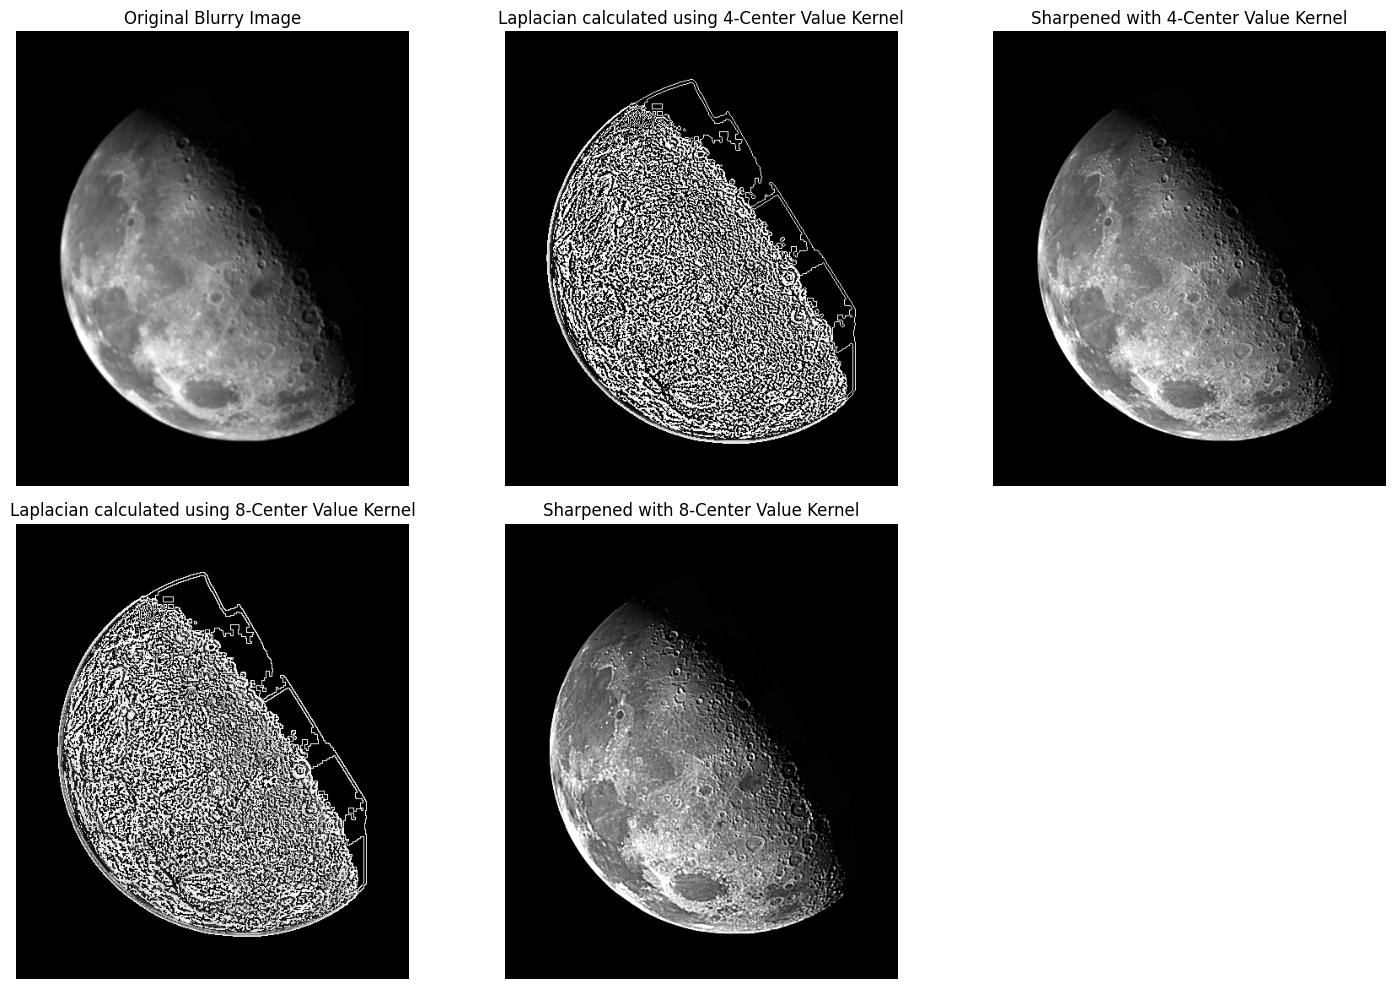

In [ ]:
try:
    img_original = cv2.imread(image_path / 'moon_blur.tif', cv2.IMREAD_GRAYSCALE)

    if img_original is None:
        raise FileNotFoundError("Image not found. Please ensure that the image is in the correct directory.")

    # Apply sharpening with the Laplacian kernel
    laplacian_4, img_sharpened_4 = apply_laplacian_sharpening(img_original, laplacian_kernel)
    
    # Optional: Try a different kernel (e.g., the 8-neighbor one)
    laplacian_8_neighbor = np.array([
        [-1, -1, -1],
        [-1, 8, -1],
        [-1, -1, -1]
    ], dtype=np.float32)
    laplacian_8, img_sharpened_8 = apply_laplacian_sharpening(img_original, laplacian_8_neighbor)

    # Display results
    plt.figure(figsize=(15, 10))

    plt.subplot(2, 3, 1)
    plt.title("Original Blurry Image")
    plt.imshow(img_original, cmap='gray', vmin=0, vmax=255)
    plt.axis('off')

    plt.subplot(2, 3, 2)
    plt.title("Laplacian calculated using 4-Center Value Kernel")
    plt.imshow(laplacian_4, cmap='gray', vmin=0, vmax=255)
    plt.axis('off')

    plt.subplot(2, 3, 3)
    plt.title("Sharpened with 4-Center Value Kernel")
    plt.imshow(img_sharpened_4, cmap='gray', vmin=0, vmax=255)
    plt.axis('off')

    plt.subplot(2, 3, 4)
    plt.title("Laplacian calculated using 8-Center Value Kernel")
    plt.imshow(laplacian_8, cmap='gray', vmin=0, vmax=255)
    plt.axis('off')
    
    plt.subplot(2, 3, 5)
    plt.title("Sharpened with 8-Center Value Kernel")
    plt.imshow(img_sharpened_8, cmap='gray', vmin=0, vmax=255)
    plt.axis('off')

    plt.tight_layout()
    plt.show()

except Exception as e:
    print(f"An error occurred: {e}")

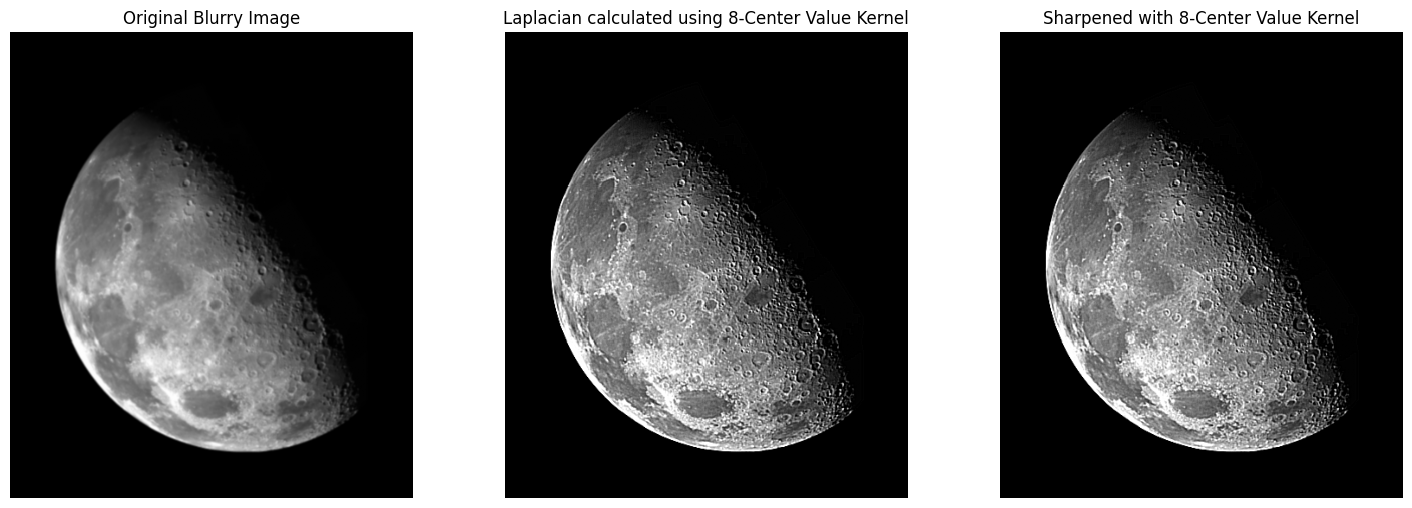

In [9]:
img_original = cv2.imread(image_path / 'moon_blur.tif', cv2.IMREAD_GRAYSCALE)
laplacian_8_neighbor = np.array([
        [-1, -1, -1],
        [-1, 8, -1],
        [-1, -1, -1]
    ], dtype=np.float32)
laplacian_8, img_sharpened_8 = apply_laplacian_sharpening(img_original, laplacian_8_neighbor)

plt.figure(figsize=(15, 10))

plt.subplot(2, 3, 1)
plt.title("Original Blurry Image")
plt.imshow(img_original, cmap='gray', vmin=0, vmax=255)
plt.axis('off')

plt.subplot(2, 3, 2)
plt.title("Laplacian calculated using 8-Center Value Kernel")
plt.imshow(img_sharpened_8, cmap='gray', vmin=0, vmax=255)
plt.axis('off')

laplacian_8, img_sharpened_8 = apply_laplacian_sharpening(img_original, laplacian_8_neighbor)
plt.subplot(2, 3, 3)
plt.title("Sharpened with 8-Center Value Kernel")
plt.imshow(img_sharpened_8, cmap='gray', vmin=0, vmax=255)
plt.axis('off')
    
plt.tight_layout()
plt.show()